In [1]:
# https://github.com/jeandeducla/ML-Time-Series/blob/master/SVM-Accelerometer.ipynb
import pandas as pd
import numpy as np
import datetime as dt

In [2]:
import scipy.stats as st
from scipy.fftpack import fft, fftfreq 
from scipy.signal import argrelextrema
import operator

In [3]:
df=pd.read_csv('data_ref_until_2020-02-13.csv')

In [4]:
df.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,2020-01-25 00:01:49.251503+01:00,20.64,55.57,121.0,496.0,521.0,694.0,652.0,591.0,135.0
1,2020-01-25 00:02:09.350082+01:00,20.64,55.53,122.0,495.0,521.0,694.0,652.0,591.0,135.0
2,2020-01-25 00:02:29.319505+01:00,20.62,55.53,121.0,495.0,522.0,694.0,651.0,591.0,135.0
3,2020-01-25 00:02:49.399379+01:00,20.62,55.57,121.0,495.0,522.0,694.0,651.0,591.0,135.0
4,2020-01-25 00:03:09.158989+01:00,20.62,55.59,121.0,495.0,522.0,694.0,652.0,591.0,135.0


In [5]:
# need to convert time string to time format for easy processing
df['recordtime'] = df['timestamp']
df.recordtime =df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.recordtime =df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [6]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
df.sort_values(by='recordtime', inplace=True, ascending=True)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.floor(freq='1H')

In [7]:
# always check the latest data
df.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
0,2020-01-25 00:00:00+01:00,20.64,55.57,121.0,496.0,521.0,694.0,652.0,591.0,135.0,2020-01-25 00:01:49
1,2020-01-25 00:00:00+01:00,20.64,55.53,122.0,495.0,521.0,694.0,652.0,591.0,135.0,2020-01-25 00:02:09
2,2020-01-25 00:00:00+01:00,20.62,55.53,121.0,495.0,522.0,694.0,651.0,591.0,135.0,2020-01-25 00:02:29
3,2020-01-25 00:00:00+01:00,20.62,55.57,121.0,495.0,522.0,694.0,651.0,591.0,135.0,2020-01-25 00:02:49
4,2020-01-25 00:00:00+01:00,20.62,55.59,121.0,495.0,522.0,694.0,652.0,591.0,135.0,2020-01-25 00:03:09


In [8]:
df.tail()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
75506,2020-02-13 11:00:00+01:00,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0,2020-02-13 11:56:53
75507,2020-02-13 11:00:00+01:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2020-02-13 11:57:14
75508,2020-02-13 11:00:00+01:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2020-02-13 11:57:33
75509,2020-02-13 11:00:00+01:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2020-02-13 11:57:54
75510,2020-02-13 11:00:00+01:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2020-02-13 11:58:14


In [9]:
df.shape

(75511, 11)

In [10]:
# look the count for each time group
group_count = pd.DataFrame(df.groupby('timestamp').count()['humidity'])
group_count.reset_index(inplace=True)
group_count.rename(columns={"humidity": "countv"}, inplace=True)

In [11]:
# some of the time group has low number of data missing
# Fillup them
group_count.countv.unique()

array([175, 180, 125, 157, 164, 171, 162,  86, 178, 146, 148,  47,  94,
       145,  98, 179, 181])

In [12]:
# these time group has low count - 
# lot of data is missing for these. So they need to be removed
time_low_count = group_count[group_count.countv<150]
time_low_count

,timestamp,countv
22,2020-01-25 22:00:00+01:00,125
31,2020-01-26 07:00:00+01:00,86
35,2020-01-26 11:00:00+01:00,146
36,2020-01-26 12:00:00+01:00,148
206,2020-02-02 14:00:00+01:00,47
207,2020-02-04 12:00:00+01:00,94
245,2020-02-06 02:00:00+01:00,145
246,2020-02-06 03:00:00+01:00,98


In [13]:
# np.unique([(list(df.recordtime)[i] - list(df.recordtime)[i-1]).seconds for i in range(1, len(df.recordtime))])

In [14]:
df.columns

Index(['timestamp', 'temperature', 'humidity', 'CO2CosIRValue',
       'CO2MG811Value', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'COValue',
       'recordtime'],
      dtype='object')

In [15]:
# investigate how these data is missing
processed_df = df[['temperature', 'humidity', 'CO2CosIRValue','CO2MG811Value', 'MOX1', 'MOX4', 'COValue']].copy()
processed_df['timestamp'] = df['timestamp']
processed_df['recordtime'] = df['recordtime']

In [16]:
# ndf = pd.DataFrame(columns=df.columns)
# for time in df.recordtime:
#     current_value = list(df[df.recordtime==time].values[0])
#     ndf.loc[len(ndf)] = current_value

#     next_time = time + dt.timedelta(seconds=22)
#     temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#     if len(temp) < 1:
#         current_value[-1] = next_time
#         ndf.loc[len(ndf)] = current_value

#         next_time = next_time + dt.timedelta(seconds=22)
#         temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#         if len(temp) < 1:
#             current_value[-1] = next_time
#             ndf.loc[len(ndf)] = current_value

In [17]:
processed_df=processed_df[~processed_df.timestamp.isin(time_low_count.timestamp)]

In [18]:
processed_df.shape

(74622, 9)

In [19]:
group_count = group_count[~group_count.timestamp.isin(time_low_count.timestamp)]

In [20]:
group_count.shape

(415, 2)

In [21]:
import numpy as np
import pandas as pd

def stat_area_features1(x):
    mean_ts = np.mean(x, axis=1).reshape(-1, 1)  # mean
    std_ts = np.std(x, axis=1).reshape(-1, 1)    # std
    return np.concatenate((mean_ts, std_ts), axis=1)

def make_feature1(data, column_name):
    # Convert data into list of lists
    x = convert_to_list(data, column_name)

    # Extract statistical features
    x_stat = stat_area_features1(x)
    x_stat = pd.DataFrame(x_stat)
    # Rename columns with desired format
    x_stat.columns = [f"{column_name}_{stat}" for stat in ['mean', 'std'] for i in range(x_stat.shape[1] // 2)]
    
    return x_stat

In [24]:
# Get for all columns
features_df = group_count.copy()
for column_name in processed_df.columns:
    if column_name not in ("timestamp", 'recordtime'):
        ndf=make_feature1(processed_df, column_name=column_name)
        features_df=pd.concat([features_df, ndf], axis=1)
    print(column_name)

temperature
humidity
CO2CosIRValue
CO2MG811Value
MOX1
MOX4
COValue
timestamp
recordtime


In [76]:
def stat_area_features(x, Te=1.0):

    mean_ts = np.mean(x, axis=1).reshape(-1,1) # mean
    max_ts = np.amax(x, axis=1).reshape(-1,1) # max
    min_ts = np.amin(x, axis=1).reshape(-1,1) # min
    std_ts = np.std(x, axis=1).reshape(-1,1) # std
    skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
    kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis 
    iqr_ts = st.iqr(x, axis=1).reshape(-1,1) # interquartile rante
    mad_ts = np.median(np.sort(abs(x - np.median(x, axis=1).reshape(-1,1)),
                               axis=1), axis=1).reshape(-1,1) # median absolute deviation
    area_ts = np.trapz(x, axis=1, dx=Te).reshape(-1,1) # area under curve
    sq_area_ts = np.trapz(x ** 2, axis=1, dx=Te).reshape(-1,1) # area under curve ** 2

    return np.concatenate((mean_ts,max_ts,min_ts,std_ts,skew_ts,kurtosis_ts,
                           iqr_ts,mad_ts,area_ts,sq_area_ts), axis=1)

In [77]:
def frequency_domain_features(x, Te=1.0):

    # As the DFT coefficients and their corresponding frequencies are symetrical arrays
    # with respect to the middle of the array we need to know if the number of readings 
    # in x is even or odd to then split the arrays...
    if x.shape[1]%2 == 0:
        N = int(x.shape[1]/2)
    else:
        N = int(x.shape[1]/2) - 1
    xf = np.repeat(fftfreq(x.shape[1],d=Te)[:N].reshape(1,-1), x.shape[0], axis=0) # frequencies
    dft = np.abs(fft(x, axis=1))[:,:N] # DFT coefficients   
    
    # statistical and area features
    dft_features = stat_area_features(dft, Te=1.0)
    # weighted mean frequency
    dft_weighted_mean_f = np.average(xf, axis=1, weights=dft).reshape(-1,1)
    # 5 first DFT coefficients 
    dft_first_coef = dft[:,:5]    
    # 5 first local maxima of DFT coefficients and their corresponding frequencies
    dft_max_coef = np.zeros((x.shape[0],5))
    dft_max_coef_f = np.zeros((x.shape[0],5))
    for row in range(x.shape[0]):
        # finds all local maximas indexes
        extrema_ind = argrelextrema(dft[row,:], np.greater, axis=0) 
        # makes a list of tuples (DFT_i, f_i) of all the local maxima
        # and keeps the 5 biggest...
        extrema_row = sorted([(dft[row,:][j],xf[row,j]) for j in extrema_ind[0]],
                             key=operator.itemgetter(0), reverse=True)[:5] 
        for i, ext in enumerate(extrema_row):
            dft_max_coef[row,i] = ext[0]
            dft_max_coef_f[row,i] = ext[1]    
    
    return np.concatenate((dft_features,dft_weighted_mean_f,dft_first_coef,
                           dft_max_coef,dft_max_coef_f), axis=1)


In [23]:
def convert_to_list(data, column_name):
    Unique_time = data.timestamp.unique()
    X = []
    for time in Unique_time:
        values = data[data.timestamp==time][column_name].tolist()
        if len(values)<181:
            resample_len=181-len(values)
            new_data = [np.mean(values)] * resample_len
            values.extend(new_data)
        X.append(values)
    return np.array(X)

In [79]:
def make_feature(data, column_name, Te=1.0):
    # convert data into list of lists
    x=convert_to_list(data, column_name)

    # extract statistical feature
    x_stat=stat_area_features(x)
    x_stat=pd.DataFrame(x_stat)
    x_stat.columns=[column_name+'_stat_'+ str(i) for i in range(x_stat.shape[1])]

    # extract statistical feature for the signal difference
    xt_jerk = stat_area_features((x[:, 1:]-x[:, :-1])/Te, Te=Te)
    xt_jerk = pd.DataFrame(xt_jerk)
    xt_jerk.columns=[column_name + '_xt_jerk_' + str(i) for i in range(xt_jerk.shape[1])]
    x_final=pd.concat([x_stat, xt_jerk], axis=1)

    
    # extract frequency_domain_features
    x_domain=frequency_domain_features(x)
    x_domain=pd.DataFrame(x_domain)
    x_domain.columns=[column_name +'_tm_dom_'+ str(i) for i in range(x_domain.shape[1])]
    x_final = pd.concat([x_final, x_domain], axis=1)

    # extract frequency_domain_features for the signal difference
    xf_jerk = frequency_domain_features((x[:, 1:]-x[:, :-1])/Te, Te=1/Te)
    xf_jerk = pd.DataFrame(xf_jerk)
    xf_jerk.columns=[column_name + '_xf_jerk_' + str(i) for i in range(xf_jerk.shape[1])]
    x_final = pd.concat([x_final, xf_jerk], axis=1)

    return x_final

In [80]:
# test only for humidity column
humidity=make_feature(processed_df, column_name='humidity')

In [81]:
humidity.head()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
0,56.078725,57.149105,55.430950,0.431106,0.359295,-1.147222,0.811836,0.361805,10094.411384,566128.751804,...,4.275414,4.252218,3.801071,3.734776,3.464367,0.238889,0.411111,0.194444,0.150000,0.211111
1,51.518593,57.136220,46.287870,2.955523,0.483370,-1.033436,5.016090,2.096592,9270.614518,479034.381994,...,16.585815,15.937618,15.588574,14.736131,13.649047,0.394444,0.461111,0.427778,0.444444,0.372222
2,49.283951,50.605410,48.287790,0.522955,0.101290,-0.995996,0.898812,0.442379,8871.462252,437287.266930,...,7.559924,7.113068,7.099939,6.867343,6.803082,0.361111,0.244444,0.483333,0.433333,0.255556
3,48.557931,50.540905,48.049644,0.354589,2.165207,6.701373,0.331330,0.123884,8740.484021,424445.312108,...,8.255924,7.046343,6.509563,6.464868,6.320376,0.244444,0.394444,0.427778,0.450000,0.416667
4,48.605383,50.344303,47.948130,0.372127,0.839437,3.034918,0.387660,0.199506,8749.099919,425284.749130,...,6.163668,5.718226,5.456958,4.730212,4.387916,0.222222,0.166667,0.177778,0.283333,0.205556


In [82]:
humidity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 72 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   humidity_stat_0      415 non-null    float64
 1   humidity_stat_1      415 non-null    float64
 2   humidity_stat_2      415 non-null    float64
 3   humidity_stat_3      415 non-null    float64
 4   humidity_stat_4      415 non-null    float64
 5   humidity_stat_5      415 non-null    float64
 6   humidity_stat_6      415 non-null    float64
 7   humidity_stat_7      415 non-null    float64
 8   humidity_stat_8      415 non-null    float64
 9   humidity_stat_9      415 non-null    float64
 10  humidity_xt_jerk_0   415 non-null    float64
 11  humidity_xt_jerk_1   415 non-null    float64
 12  humidity_xt_jerk_2   415 non-null    float64
 13  humidity_xt_jerk_3   415 non-null    float64
 14  humidity_xt_jerk_4   415 non-null    float64
 15  humidity_xt_jerk_5   415 non-null    flo

In [83]:
humidity.describe()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
count,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,...,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000
mean,56.675336,57.531440,55.785871,0.408901,-0.065912,0.053305,0.608823,0.273138,10201.564624,579212.508113,...,4.740348,4.247041,3.947619,3.704435,3.549919,0.322758,0.331486,0.318461,0.312115,0.303199
std,2.331234,2.401554,2.412110,0.402861,0.673954,1.679737,0.735884,0.313518,419.616392,46444.158777,...,2.563761,2.265284,2.086244,1.971657,1.908579,0.114604,0.106692,0.121447,0.120792,0.118612
min,47.297171,47.516266,46.006306,0.043371,-3.527857,-1.736692,0.039452,0.019661,8513.418737,402659.216567,...,0.728052,0.645634,0.570499,0.570110,0.559160,0.005556,0.005556,0.011111,0.005556,0.011111
25%,55.334134,56.159237,54.721758,0.241356,-0.441582,-0.864956,0.303959,0.148508,9960.178855,551144.530766,...,3.318156,3.032071,2.765839,2.612898,2.525344,0.238889,0.255556,0.233333,0.227778,0.216667
50%,57.092297,57.874830,56.093540,0.311416,-0.050950,-0.408728,0.420571,0.202671,10276.382943,586706.594908,...,4.160234,3.813961,3.533680,3.324896,3.198366,0.333333,0.338889,0.333333,0.333333,0.311111
75%,58.252513,58.977204,57.374658,0.413550,0.313051,0.398254,0.604050,0.289434,10485.499233,610828.447541,...,5.408851,4.912002,4.573156,4.210287,4.022985,0.419444,0.416667,0.419444,0.411111,0.405556
max,63.282213,69.303215,62.328476,3.424976,2.165207,13.486328,6.516410,3.169807,11390.608762,720932.355732,...,20.640091,20.238771,17.847660,17.586983,17.283325,0.488889,0.488889,0.488889,0.488889,0.488889


In [84]:
# Get for all columns
features_df = group_count.copy()
for column_name in processed_df.columns:
    if column_name not in ("timestamp", 'recordtime'):
        ndf=make_feature(processed_df, column_name=column_name)
        features_df=pd.concat([features_df, ndf], axis=1)
    print(column_name)

temperature
humidity
CO2CosIRValue
CO2MG811Value
MOX1
MOX4
COValue
timestamp
recordtime


In [85]:
features_df.shape

(423, 506)

In [86]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 423 entries, 0 to 246
Columns: 506 entries, timestamp to COValue_xf_jerk_25
dtypes: datetime64[ns, pytz.FixedOffset(60)](1), float64(505)
memory usage: 1.6 MB


In [87]:
features_df.head()

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
0,2020-01-25 00:00:00+01:00,175.0,20.416646,20.804050,20.082401,0.171118,0.072622,-0.861293,0.305056,0.144031,...,26.306608,22.169923,21.340352,21.145341,20.734054,0.427778,0.266667,0.283333,0.200000,0.466667
1,2020-01-25 01:00:00+01:00,180.0,19.574341,20.214909,19.099243,0.282481,0.536670,-0.569746,0.404609,0.191643,...,28.094593,26.405473,24.700605,24.691823,23.750821,0.461111,0.238889,0.166667,0.350000,0.277778
2,2020-01-25 02:00:00+01:00,180.0,18.796782,19.127120,18.547720,0.138663,0.574657,-0.134832,0.164511,0.080529,...,18.220365,18.176702,17.763530,17.594287,17.121185,0.294444,0.488889,0.427778,0.322222,0.405556
3,2020-01-25 03:00:00+01:00,180.0,18.467034,18.668068,18.298264,0.094657,0.134284,-0.951397,0.161499,0.067265,...,8.228963,8.095122,7.204726,6.830691,6.074365,0.383333,0.194444,0.327778,0.155556,0.144444
4,2020-01-25 04:00:00+01:00,180.0,18.036708,18.293518,17.848309,0.094560,0.519670,0.799679,0.092564,0.048958,...,16.013884,14.001331,12.531661,12.193032,11.123635,0.466667,0.483333,0.283333,0.150000,0.405556


In [25]:
features_df.describe()

,countv,temperature_mean,temperature_std,humidity_mean,humidity_std,CO2CosIRValue_mean,CO2CosIRValue_std,CO2MG811Value_mean,CO2MG811Value_std,MOX1_mean,MOX1_std,MOX4_mean,MOX4_std,COValue_mean,COValue_std
count,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000,415.000000
mean,179.812048,20.053225,0.141057,56.675046,0.390360,70.058379,1.952408,510.098157,0.647446,538.558719,2.135192,624.911345,2.874879,114.184188,1.578133
std,1.724602,1.355449,0.078462,2.348868,0.407019,22.793180,2.939177,8.892615,0.751465,20.688711,3.564582,27.509885,4.011426,20.183332,2.613194
min,157.000000,15.086444,0.034963,47.261167,0.060699,41.083333,0.583037,495.708571,0.180715,436.872222,0.404699,484.472222,0.217342,83.272222,0.452556
25%,180.000000,19.987389,0.097169,55.316361,0.217784,52.800000,0.956930,502.163889,0.440366,530.188889,0.906358,610.588889,1.161421,100.750000,0.713368
50%,180.000000,20.198333,0.129113,57.037000,0.290964,69.405556,1.115712,508.590643,0.488543,536.577778,1.229310,625.594444,1.875171,109.516667,0.924132
75%,180.000000,20.641111,0.160282,58.261917,0.390945,73.483333,1.461988,518.338889,0.536998,545.166667,2.101692,642.782666,2.913926,119.577778,1.449995
max,181.000000,23.080000,0.782418,63.277278,3.422218,161.322222,29.474143,525.527778,7.472058,596.477778,43.559831,688.316667,35.041158,185.277778,39.449815


In [89]:
features_stat_df = pd.DataFrame(features_df.describe())

In [26]:
processed_features_df = features_df.copy()
processed_features_df['timestamp'] = features_df['timestamp']
processed_features_df.dropna(inplace=True)
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [27]:
processed_features_df.head()

,timestamp,countv,temperature_mean,temperature_std,humidity_mean,humidity_std,CO2CosIRValue_mean,CO2CosIRValue_std,CO2MG811Value_mean,CO2MG811Value_std,MOX1_mean,MOX1_std,MOX4_mean,MOX4_std,COValue_mean,COValue_std
0,2020-01-25 00:00:00,175.0,20.420286,0.173270,56.059257,0.447027,121.702857,1.457593,495.708571,0.493813,523.822857,1.001404,593.382857,1.637524,131.342857,1.931748
1,2020-01-25 01:00:00,180.0,19.564944,0.275664,51.453833,2.962199,95.866667,17.840112,500.422222,3.654945,540.333333,9.233616,617.005556,15.581012,121.200000,5.215150
2,2020-01-25 02:00:00,180.0,18.798389,0.130605,49.258778,0.472122,65.794444,2.614657,507.422222,0.820696,564.072222,4.494356,653.416667,6.404311,103.733333,4.765901
3,2020-01-25 03:00:00,180.0,18.469889,0.112422,48.545833,0.341124,61.816667,0.999862,508.922222,0.463658,572.755556,1.140041,665.538889,0.796150,93.705556,0.864891
4,2020-01-25 04:00:00,180.0,18.035556,0.091188,48.636944,0.314116,61.983333,1.158562,509.244444,0.428569,577.661111,1.490908,670.338889,2.274441,90.522222,1.683378


In [28]:
processed_features_df['timestamp']

0     2020-01-25 00:00:00
1     2020-01-25 01:00:00
2     2020-01-25 02:00:00
3     2020-01-25 03:00:00
4     2020-01-25 04:00:00
              ...        
410   2020-02-12 23:00:00
411   2020-02-13 00:00:00
412   2020-02-13 01:00:00
413   2020-02-13 02:00:00
414   2020-02-13 03:00:00
Name: timestamp, Length: 407, dtype: datetime64[ns]

In [29]:
processed_features_df.describe()

,countv,temperature_mean,temperature_std,humidity_mean,humidity_std,CO2CosIRValue_mean,CO2CosIRValue_std,CO2MG811Value_mean,CO2MG811Value_std,MOX1_mean,MOX1_std,MOX4_mean,MOX4_std,COValue_mean,COValue_std
count,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000
mean,179.820639,20.076394,0.141015,56.655015,0.391844,69.656318,1.953458,510.099875,0.649048,538.424795,2.155201,624.657587,2.910152,114.242930,1.590402
std,1.724859,1.315223,0.077934,2.330639,0.408655,22.409476,2.964688,8.925263,0.758309,20.428484,3.594719,27.450448,4.040251,20.252476,2.635931
min,157.000000,15.086444,0.034963,47.261167,0.060699,41.083333,0.583037,495.708571,0.180715,436.872222,0.404699,484.472222,0.217342,83.272222,0.479762
25%,180.000000,19.990472,0.097182,55.316361,0.220169,52.066667,0.955903,502.022222,0.439425,530.188889,0.919771,610.588889,1.187091,100.783333,0.716528
50%,180.000000,20.198333,0.129746,57.026778,0.291505,69.244444,1.110956,508.661111,0.488794,536.550000,1.249629,625.416667,1.894031,109.633333,0.929101
75%,180.000000,20.641111,0.160282,58.245389,0.390945,73.380556,1.418732,518.338889,0.536998,545.088889,2.126936,642.372222,2.925937,119.577778,1.456066
max,181.000000,23.080000,0.782418,63.277278,3.422218,161.322222,29.474143,525.527778,7.472058,596.477778,43.559831,688.316667,35.041158,185.277778,39.449815


In [30]:

# Adding a new column named 'total_count' with float data type and all values set to 0
processed_features_df = processed_features_df.assign(total_count=0.0)

In [33]:
processed_features_df

,timestamp,temperature_mean,temperature_std,humidity_mean,humidity_std,CO2CosIRValue_mean,CO2CosIRValue_std,CO2MG811Value_mean,CO2MG811Value_std,MOX1_mean,MOX1_std,MOX4_mean,MOX4_std,COValue_mean,COValue_std,total_count
0,2020-01-25 00:00:00,20.420286,0.173270,56.059257,0.447027,121.702857,1.457593,495.708571,0.493813,523.822857,1.001404,593.382857,1.637524,131.342857,1.931748,0.0
1,2020-01-25 01:00:00,19.564944,0.275664,51.453833,2.962199,95.866667,17.840112,500.422222,3.654945,540.333333,9.233616,617.005556,15.581012,121.200000,5.215150,0.0
2,2020-01-25 02:00:00,18.798389,0.130605,49.258778,0.472122,65.794444,2.614657,507.422222,0.820696,564.072222,4.494356,653.416667,6.404311,103.733333,4.765901,0.0
3,2020-01-25 03:00:00,18.469889,0.112422,48.545833,0.341124,61.816667,0.999862,508.922222,0.463658,572.755556,1.140041,665.538889,0.796150,93.705556,0.864891,0.0
4,2020-01-25 04:00:00,18.035556,0.091188,48.636944,0.314116,61.983333,1.158562,509.244444,0.428569,577.661111,1.490908,670.338889,2.274441,90.522222,1.683378,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,2020-02-12 23:00:00,20.275222,0.147046,58.441167,0.389594,43.233333,0.873805,518.155556,0.456049,528.961111,1.331156,599.111111,0.933649,148.238889,2.108556,0.0
411,2020-02-13 00:00:00,20.341500,0.175595,58.252778,0.253377,42.883333,1.036755,518.011111,0.504005,530.033333,0.957090,600.761111,0.700149,149.438889,2.490122,0.0
412,2020-02-13 01:00:00,20.396167,0.169853,57.806222,0.266046,42.988889,1.225822,518.072222,0.433801,530.455556,1.249629,601.194444,0.631557,148.750000,2.520359,0.0
413,2020-02-13 02:00:00,20.337611,0.126663,57.908111,0.294849,43.650000,0.894890,518.077778,0.267081,529.527778,1.404140,597.183333,1.495758,150.288889,1.119831,0.0


In [96]:
keep_list=['CO2CosIRValue_stat_3',
 'CO2CosIRValue_stat_9',
 'CO2CosIRValue_xf_jerk_2',
 'CO2CosIRValue_xf_jerk_11',
 'CO2CosIRValue_xf_jerk_15',
 'COValue_stat_3',
 'COValue_stat_9',
 'total_count']

In [42]:
keep_list.append('timestamp')

In [97]:
final_features_df = processed_features_df[keep_list].copy()
final_features_df.head()

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_9,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_11,CO2CosIRValue_xf_jerk_15,COValue_stat_3,COValue_stat_9,total_count
0,1.658763,2.661628e+06,0.547523,0.547523,6.970635,1.914369,3.102724e+06,0.0
1,17.834314,1.706289e+06,3.821384,25.255760,48.602210,5.286577,2.649853e+06,0.0
2,2.518447,7.809517e+05,0.898573,4.800944,4.524965,4.790138,1.939998e+06,0.0
3,0.570912,6.873675e+05,0.281250,0.429434,2.332140,0.587819,1.581815e+06,0.0
4,0.762610,6.916867e+05,0.293167,0.293167,2.607404,1.554069,1.475875e+06,0.0


In [98]:
final_features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 407 entries, 0 to 414
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CO2CosIRValue_stat_3      407 non-null    float64
 1   CO2CosIRValue_stat_9      407 non-null    float64
 2   CO2CosIRValue_xf_jerk_2   407 non-null    float64
 3   CO2CosIRValue_xf_jerk_11  407 non-null    float64
 4   CO2CosIRValue_xf_jerk_15  407 non-null    float64
 5   COValue_stat_3            407 non-null    float64
 6   COValue_stat_9            407 non-null    float64
 7   total_count               407 non-null    float64
dtypes: float64(8)
memory usage: 28.6 KB


In [45]:
del final_features_df['timestamp']

In [46]:
final_features_df.to_csv('Raw_data_no_candidate_v2.csv')

In [47]:
final_features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 415 entries, 0 to 418
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CO2CosIRValue_stat_3      415 non-null    float64
 1   CO2CosIRValue_stat_9      415 non-null    float64
 2   CO2CosIRValue_xt_jerk_1   415 non-null    float64
 3   CO2CosIRValue_xt_jerk_5   415 non-null    float64
 4   CO2CosIRValue_xt_jerk_6   415 non-null    float64
 5   CO2CosIRValue_tm_dom_16   415 non-null    float64
 6   CO2CosIRValue_xf_jerk_9   415 non-null    float64
 7   CO2CosIRValue_xf_jerk_14  415 non-null    float64
 8   CO2CosIRValue_xf_jerk_15  415 non-null    float64
 9   COValue_stat_7            415 non-null    float64
 10  COValue_stat_9            415 non-null    float64
 11  COValue_xt_jerk_1         415 non-null    float64
 12  COValue_xt_jerk_5         415 non-null    float64
 13  COValue_xt_jerk_7         415 non-null    float64
 14  COValue_tm

In [36]:
drop_features = ['Living room', 'Bedroom', 'Bathroom', 'Kitchen', 'Unnamed: 0']

In [34]:
df=pd.read_csv('data1.csv')

In [37]:
df = df.drop(drop_features, axis=1)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2295 entries, 0 to 2294
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           2295 non-null   object 
 1   temperature_mean    2295 non-null   float64
 2   temperature_std     2295 non-null   float64
 3   humidity_mean       2295 non-null   float64
 4   humidity_std        2295 non-null   float64
 5   CO2CosIRValue_mean  2295 non-null   float64
 6   CO2CosIRValue_std   2295 non-null   float64
 7   CO2MG811Value_mean  2295 non-null   float64
 8   CO2MG811Value_std   2295 non-null   float64
 9   MOX1_mean           2295 non-null   float64
 10  MOX1_std            2295 non-null   float64
 11  MOX4_mean           2295 non-null   float64
 12  MOX4_std            2295 non-null   float64
 13  COValue_mean        2295 non-null   float64
 14  COValue_std         2295 non-null   float64
 15  Hallway             1531 non-null   float64
 16  total_

In [39]:
del df['Hallway']

In [110]:
df.rename(columns={'total_count.1': 'total_count'}, inplace=True)

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2295 entries, 0 to 2294
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           2295 non-null   object 
 1   temperature_mean    2295 non-null   float64
 2   temperature_std     2295 non-null   float64
 3   humidity_mean       2295 non-null   float64
 4   humidity_std        2295 non-null   float64
 5   CO2CosIRValue_mean  2295 non-null   float64
 6   CO2CosIRValue_std   2295 non-null   float64
 7   CO2MG811Value_mean  2295 non-null   float64
 8   CO2MG811Value_std   2295 non-null   float64
 9   MOX1_mean           2295 non-null   float64
 10  MOX1_std            2295 non-null   float64
 11  MOX4_mean           2295 non-null   float64
 12  MOX4_std            2295 non-null   float64
 13  COValue_mean        2295 non-null   float64
 14  COValue_std         2295 non-null   float64
 15  total_count         1531 non-null   float64
dtypes: flo

In [41]:
frame=[df,processed_features_df]

In [42]:
final_data=pd.concat(frame)

In [43]:
final_data

,timestamp,temperature_mean,temperature_std,humidity_mean,humidity_std,CO2CosIRValue_mean,CO2CosIRValue_std,CO2MG811Value_mean,CO2MG811Value_std,MOX1_mean,MOX1_std,MOX4_mean,MOX4_std,COValue_mean,COValue_std,total_count
0,2019-11-06 12:00:00,19.699111,0.395877,51.239833,0.974251,84.727778,4.295482,616.772222,2.455866,530.872222,4.325219,622.116667,6.680784,95.533333,1.104486,12.0
1,2019-11-06 13:00:00,20.202778,0.359069,49.903167,1.064936,81.994444,4.713326,618.461111,2.911900,427.705556,50.685325,625.294444,13.142524,111.450000,7.241894,2.0
2,2019-11-06 14:00:00,20.311944,0.292424,50.692444,1.037522,85.977778,2.930042,615.988889,1.394499,385.505556,23.892600,621.472222,3.899895,107.855556,1.907016,8.0
3,2019-11-06 15:00:00,19.517598,0.250620,53.560223,0.621436,86.983240,1.010852,616.396648,0.560377,409.351955,18.774737,621.206704,2.462259,108.284916,1.138161,9.0
4,2019-11-06 16:00:00,21.391667,0.482690,51.769722,0.845987,94.544444,4.803684,611.138889,2.453465,472.061111,6.851353,618.666667,4.099589,116.255556,2.376501,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,2020-02-12 23:00:00,20.275222,0.147046,58.441167,0.389594,43.233333,0.873805,518.155556,0.456049,528.961111,1.331156,599.111111,0.933649,148.238889,2.108556,0.0
411,2020-02-13 00:00:00,20.341500,0.175595,58.252778,0.253377,42.883333,1.036755,518.011111,0.504005,530.033333,0.957090,600.761111,0.700149,149.438889,2.490122,0.0
412,2020-02-13 01:00:00,20.396167,0.169853,57.806222,0.266046,42.988889,1.225822,518.072222,0.433801,530.455556,1.249629,601.194444,0.631557,148.750000,2.520359,0.0
413,2020-02-13 02:00:00,20.337611,0.126663,57.908111,0.294849,43.650000,0.894890,518.077778,0.267081,529.527778,1.404140,597.183333,1.495758,150.288889,1.119831,0.0


In [45]:
final_data.dropna(inplace=True)

In [46]:
final_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1938 entries, 0 to 414
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           1938 non-null   object 
 1   temperature_mean    1938 non-null   float64
 2   temperature_std     1938 non-null   float64
 3   humidity_mean       1938 non-null   float64
 4   humidity_std        1938 non-null   float64
 5   CO2CosIRValue_mean  1938 non-null   float64
 6   CO2CosIRValue_std   1938 non-null   float64
 7   CO2MG811Value_mean  1938 non-null   float64
 8   CO2MG811Value_std   1938 non-null   float64
 9   MOX1_mean           1938 non-null   float64
 10  MOX1_std            1938 non-null   float64
 11  MOX4_mean           1938 non-null   float64
 12  MOX4_std            1938 non-null   float64
 13  COValue_mean        1938 non-null   float64
 14  COValue_std         1938 non-null   float64
 15  total_count         1938 non-null   float64
dtypes: floa

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_27746/3813215017.py:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = final_data.corr()


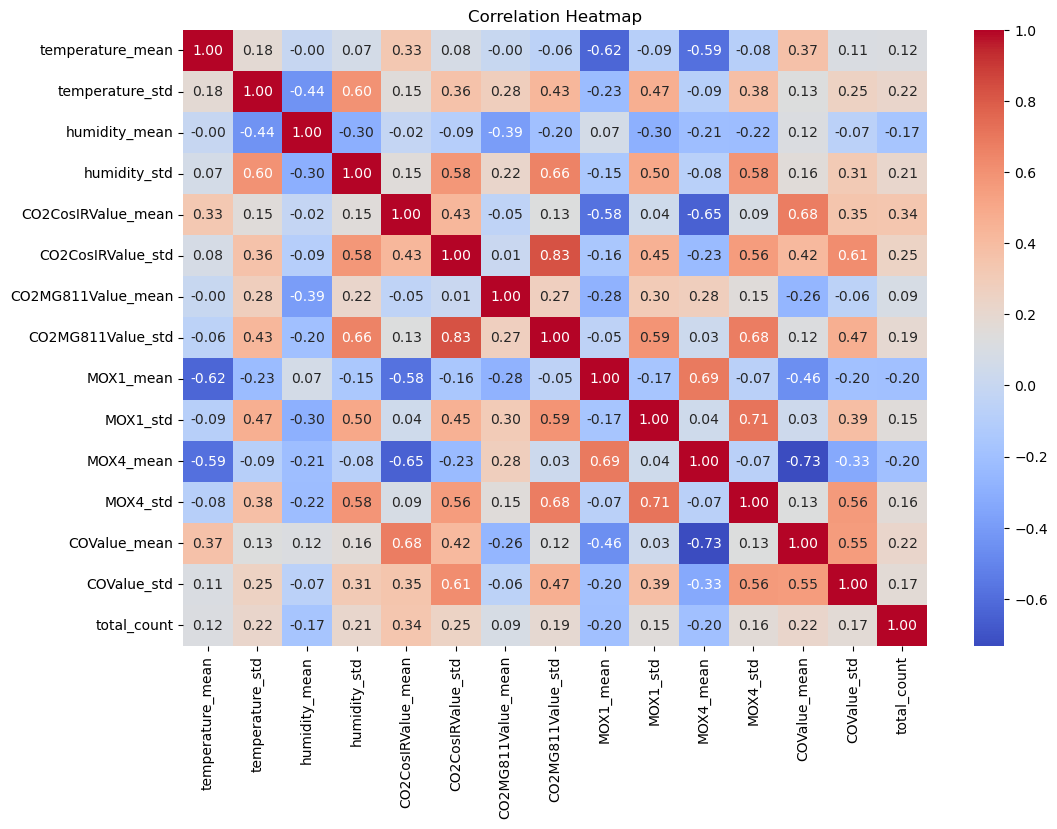

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
correlation_matrix = final_data.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

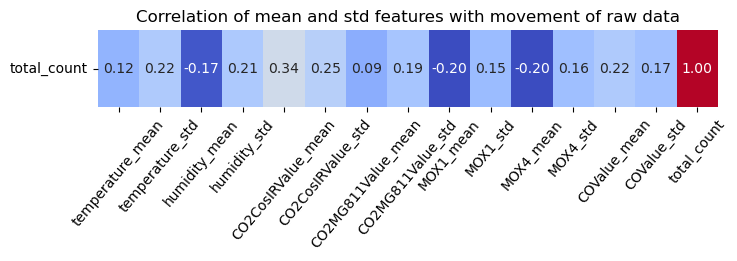

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# Your code to generate top_correlation_matrix

# Extract only the last row (which corresponds to 'total_count')
total_count_corr = correlation_matrix.iloc[-1:]

# Create a heatmap for the last row
plt.figure(figsize=(8, 1))  # Adjust the figure size as needed
heatmap = sns.heatmap(total_count_corr, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)

plt.title("Correlation of mean and std features with movement of raw data")
plt.xticks(rotation=50)  # Rotate x-axis labels if needed
plt.yticks(rotation=0)   # Rotate y-axis labels if needed
plt.show()

In [107]:
final_data.to_csv('Merge_data_value_pred_data_v2.csv')